PROJECT NAME

Brain Tumor MRI Image Classification

PROJECT SUMMARY

This project builds and compares deep learning models for classifying brain MRI images into four categories: glioma, meningioma, pituitary tumor, and no tumor. It uses the supplied training, validation, and test datasets, with steps for image quality checks, label verification, preprocessing, augmentation, and visual exploration.

A custom CNN is compared with MobileNetV2 transfer learning. Their performance is assessed using accuracy, precision, recall, F1-score, classification reports, and confusion matrices. The selected model is saved with its class labels and prepared for a Streamlit application that demonstrates image-based predictions.

The project provides an end-to-end educational image-classification workflow, from dataset preparation through model evaluation and deployment. Its predictions are for research and demonstration only and should not be used as a medical diagnosis.
This project develops an end-to-end deep learning workflow for classifying brain MRI images into four categories: glioma, meningioma, pituitary tumor, and no tumor. It explores the dataset, prepares and visualizes the images, trains and compares a custom CNN with a pretrained MobileNetV2 model, and prepares the selected model for a Streamlit demonstration app.

Phase 1: Project Setup and Dataset Review
Load the supplied training, validation, and test datasets. Inspect class counts, image dimensions, sample images, and label files to understand the data and identify quality issues.

Phase 2: Data Cleaning and Preparation
Check for unreadable and duplicate images, verify labels against the class folders, and review optional metadata. Resize images to a consistent input size, normalize pixel values, and apply augmentation to training images only.

Phase 3: Data Visualization
Compare representative images across classes and examine class distribution, image dimensions, brightness, and contrast. Review training curves, validation metrics, and confusion matrices to understand model behavior and errors.

Phase 4: Model Development
Build a custom convolutional neural network from scratch, then train a MobileNetV2 transfer-learning model. Fine-tune the pretrained model to assess whether adaptation improves validation performance.

Phase 5: Evaluation and Model Selection
Compare models using accuracy, precision, recall, F1-scores, classification reports, and confusion matrices. Choose a model based on validation results, then report its performance on the held-out test set.

Phase 6: Deployment Preparation
Save the selected model and class labels, and prepare a Streamlit application that accepts an MRI image and displays the predicted class and confidence scores.

Phase 7: Reporting and Responsible Use
Document the data preparation, visual findings, model results, and limitations. This project is an educational prototype; its predictions are not a medical diagnosis and require qualified clinical review.

PROBLEM STATEMENT

This project develops a deep learning system to classify brain MRI images into four categories: glioma, meningioma, pituitary tumor, and no tumor. It compares a custom convolutional neural network (CNN) with a pretrained MobileNetV2 model using the supplied training, validation, and test datasets. The models are evaluated with class-level metrics and confusion matrices, then the selected model is prepared for a Streamlit application that demonstrates predictions on uploaded images. The application is an educational prototype and is not intended to provide medical diagnoses.

GUIDELINES OF THE PROJECT


## 1. Understand the project

The goal is to build and compare deep-learning models that classify MRI images into four dataset categories:

- Glioma
- Meningioma
- No tumor
- Pituitary

The project covers data inspection, cleaning, visualization, preprocessing, model training, evaluation, and a Streamlit demonstration. Treat the result as an educational prototype, not a diagnostic tool.

## 2. Prepare the dataset

Use the supplied `train`, `valid`, and `test` ZIP files.

- Keep the three ZIPs separate and preserve their folder structure.
- Upload all three files to Colab together.
- Keep each split’s `_classes.csv` file with its images.
- Do not combine the splits or create a new random split; the notebook checks and preserves the existing partitions.
- Retain the dataset’s attribution and license information.

The README reports 1,695 training, 502 validation, and 246 test images. Your final counts may change if unreadable or duplicate files are found and handled.

## 3. Run the notebook in order

Open the Colab notebook and run every cell from top to bottom.

- Select a GPU runtime if available; training can run on CPU but may take longer.
- Confirm that the dataset folder was found.
- Resolve any file, label, or import errors before continuing.
- If Colab disconnects, reconnect and rerun the setup and data-loading cells.

## 4. Inspect and clean the data

Before training, review:

- Image counts by class and split
- Image dimensions
- Readability and file formats
- Exact duplicate files
- Agreement between CSV labels and folder labels
- Sample images from each class

Investigate corrupt files and label mismatches. Don’t remove an unusual image just because it looks different; verify it first. Keep the original files unchanged.

## 5. Explore and visualize

Use the notebook’s visualizations to understand the dataset:

- Class counts show possible class imbalance.
- Width and height histograms show resolution variation.
- Representative images help check quality and labels.
- Brightness and contrast plots show intensity variation.
- Original-versus-augmented examples confirm that training transformations remain reasonable.

After each graph, describe what it shows and what you observed in your run. Avoid inventing findings or making clinical interpretations from sample images.

## 6. Prepare model inputs

The notebook resizes images to 224 × 224 pixels and scales pixel values to the 0–1 range. Training images are augmented with modest transformations. Validation and test images remain unchanged.

Keep augmentation appropriate to the images: transformed examples should remain recognizable and shouldn’t crop away useful content.

## 7. Train and compare models

The notebook trains:

1. A custom CNN built from convolutional, pooling, normalization, and dropout layers.
2. A MobileNetV2 transfer-learning model, first with its pretrained feature layers frozen and then with some layers fine-tuned.

Early stopping, learning-rate reduction, and model checkpoints help manage training. If a code cell fails, read the full error message and confirm that its required variables and earlier cells are available.

## 8. Evaluate results

Use validation results to select a candidate model. Reserve the test set for final evaluation.

Review:

- Accuracy
- Precision and recall
- Weighted F1 and macro F1
- Per-class classification report
- Confusion matrix

Macro F1 gives equal importance to each class, while weighted metrics account for class frequencies. In a confusion matrix, diagonal values are correct predictions; off-diagonal values show which categories the model confuses.

In your report, include the actual outputs from your Colab run. Don’t substitute example scores.

## 9. Report statistical tests carefully

The notebook includes tests for class-count balance, brightness differences across classes, and paired model errors. Explain what each test examines and report its result. A statistically significant result does not demonstrate that the model is clinically useful or safe.

## 10. Save and demonstrate the model

Save the selected `.keras` model and `class_names.json` file together. The class names must remain in the same order used by the model.

The generated Streamlit app can accept an image and show predicted categories and confidence scores. Present it as a demonstration only; confidence scores are not medical certainty.

## 11. Complete the project submission

Include:

- The executed notebook with outputs
- Dataset description and cleaning notes
- Visualizations with written observations
- Model comparison and test metrics
- Confusion matrix and class-level results
- Saved model and class-name JSON
- Streamlit app code
- Dataset attribution and license

## 12. Present the work responsibly

Explain the project workflow, the reason for each major step, and the results you actually observed. State the limitations clearly: performance depends on this dataset and setup, and the model has not been shown to generalize to other hospitals, scanners, or patient populations. All MRI interpretations and care decisions belong to qualified clinicians.

Install and import

In [ ]:
!pip -q install scikit-learn seaborn streamlit
import os, json, random, zipfile, hashlib
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_recall_fscore_support
from sklearn.utils.class_weight import compute_class_weight
from scipy.stats import chi2_contingency, f_oneway, binomtest
SEED=42; random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
IMG_SIZE=(224,224); BATCH_SIZE=32; EPOCHS=20
OUT=Path('/content/brain_tumor_outputs'); OUT.mkdir(exist_ok=True)
print('TensorFlow',tf.__version__,'GPU',tf.config.list_physical_devices('GPU'))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.3/10.3 MB 25.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 49.3 MB/s eta 0:00:00
TensorFlow 2.21.0 GPU []


Before running Colab: image handling checklist
1. Keep the three supplied ZIP files separate and unchanged: one each for train, valid, and test. In Colab's upload picker, select all three at once. Do not combine their contents or create a new random split; the fixed partitions are needed for fair validation and final testing.
2. Preserve the directory layout inside each ZIP: split folder → class folder → image files. Keep each _classes.csv beside its split's class folders because it is used for label verification. The supplied classes are glioma, meningioma, no_tumor, and pituitary.
3. Do not manually resize, recolor, compress, crop, rename, or augment source images before uploading. The notebook checks that files can be opened, detects exact duplicates, resizes copies to 224 × 224 during loading, scales pixels, and augments training batches only. This keeps validation and test images unchanged.
4. Check the class-count chart, dimension histograms, and sampled images. If an image is corrupt, visibly mislabeled, not an MRI, or appears in the wrong class folder, record and correct the dataset source before training. Do not silently delete unusual-looking scans; unusual intensity or dimensions may be valid.
5. If adding a separate metadata CSV, make sure it has one unique filename per image and retain a backup. The three provided _classes.csv files are already joined to filenames and checked against their parent class folders.
6. The dataset README states a CC BY 4.0 license and reports 2,443 images (1,695 train, 502 validation, 246 test). Keep attribution/license information with any shared submission. Do not upload patient-identifiable images or metadata to a third-party service unless you have authorization; use the provided dataset for this educational exercise.
The notebook will report any unreadable files, duplicate content, or label mismatch. Resolve unexpected issues before model training and report the final counts after cleaning.

**Upload the provided train, validation, and test ZIP files**
Upload all three supplied archives together: train-…zip, valid-…zip, and test-…zip. They already contain separate image folders by class plus _classes.csv label tables. The notebook extracts all ZIPs, checks the CSV labels against folder labels, and keeps the provided partitions intact. Do not combine and randomly re-split these images: that can leak examples across partitions and would discard the intended test set. You can also mount Drive and set DATA_ROOT to a folder containing train/, valid/, and test/.

In [ ]:
from google.colab import files
uploaded=files.upload()  # Select all three provided ZIP files in the same file picker.
zip_names=[name for name in uploaded if name.lower().endswith('.zip')]
if not zip_names: raise FileNotFoundError('Upload the train, valid, and test ZIP files.')
DATA_ROOT=Path('/content/brain_tumor_data'); DATA_ROOT.mkdir(parents=True,exist_ok=True)
for name in zip_names:
    with zipfile.ZipFile(name) as archive: archive.extractall(DATA_ROOT)
# Drive option: from google.colab import drive; drive.mount('/content/drive')
# DATA_ROOT=Path('/content/drive/MyDrive/brain_tumor_dataset')
EXTS={'.jpg','.jpeg','.png','.bmp','.webp'}
# Accept the supplied split folders; a single unsplit class-folder dataset is supported too.
partitions={}
for key,aliases in {'train':('train','training'),'valid':('valid','validation','val'),'test':('test',)}.items():
    folder=next((DATA_ROOT/a for a in aliases if (DATA_ROOT/a).is_dir()),None)
    if folder: partitions[key]=folder
if len(partitions)==3:
    DATA_DIR=DATA_ROOT; PREDEFINED_SPLITS=True
else:
    roots=[DATA_ROOT,*DATA_ROOT.rglob('*')]
    DATA_DIR=next((r for r in roots if r.is_dir() and any(d.is_dir() and any(f.suffix.lower() in EXTS for f in d.rglob('*')) for d in r.iterdir())),None)
    if DATA_DIR is None: raise FileNotFoundError('Could not find class folders. Upload all three split ZIPs or set DATA_ROOT.')
    PREDEFINED_SPLITS=False
print('Dataset root:',DATA_DIR,'| predefined train/valid/test:',PREDEFINED_SPLITS)

Saving README.dataset.txt to README.dataset.txt
Saving test-20261005T143146Z-1-001.zip to test-20261005T143146Z-1-001.zip
Saving train-20261005T143144Z-1-001.zip to train-20261005T143144Z-1-001.zip
Saving valid-20261005T143140Z-1-001.zip to valid-20261005T143140Z-1-001.zip
Dataset root: /content/brain_tumor_data | predefined train/valid/test: True


Inventory, quality checks, and examples

Label CSV join unmatched images: 0 | folder/CSV label mismatches: 0
Readable 2443 unreadable 0 duplicate contents 0
Images by split and class:
 label  glioma  meningioma  no_tumor  pituitary
split                                         
test       80          63        49         54
train     564         358       335        438
valid     161         124        99        118


,width,height
count,2443.0,2443.0
mean,640.0,640.0
std,0.0,0.0
min,640.0,640.0
25%,640.0,640.0
50%,640.0,640.0
75%,640.0,640.0
max,640.0,640.0


,filepath,filename,label,split,width,height,hash
0,/content/brain_tumor_data/train/glioma/Tr-gl_0...,Tr-gl_0549_jpg.rf.50d13e68cb686fdec2dba44f7e82...,glioma,train,640,640,a8a122e99eac7ac147beac9cf17cbcca
1,/content/brain_tumor_data/train/glioma/Tr-gl_0...,Tr-gl_0067_jpg.rf.b035bdbd1569582e1ae65620aa7d...,glioma,train,640,640,e8a0922539632d4249fd68061b0bc596
2,/content/brain_tumor_data/train/glioma/Tr-gl_0...,Tr-gl_0380_jpg.rf.428bc74b286a37957ddcb8f4473a...,glioma,train,640,640,6fd798e6be25431f41b1e1ba0a01ad94
3,/content/brain_tumor_data/train/glioma/Tr-gl_0...,Tr-gl_0547_jpg.rf.34af4ea2dd50bb77fbfb67546550...,glioma,train,640,640,dfa7d1b81d854b1b88402703df14ae89
4,/content/brain_tumor_data/train/glioma/Tr-gl_0...,Tr-gl_0313_jpg.rf.7853e11ecfa27fdd55786ab5d6bd...,glioma,train,640,640,2dda9fc382839afc8e77c006bb5dcb0d


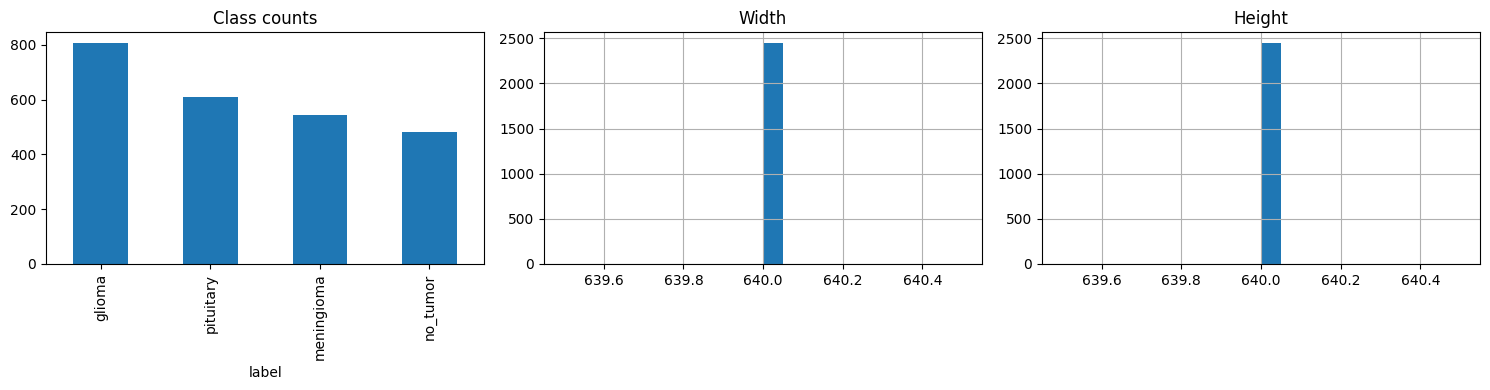

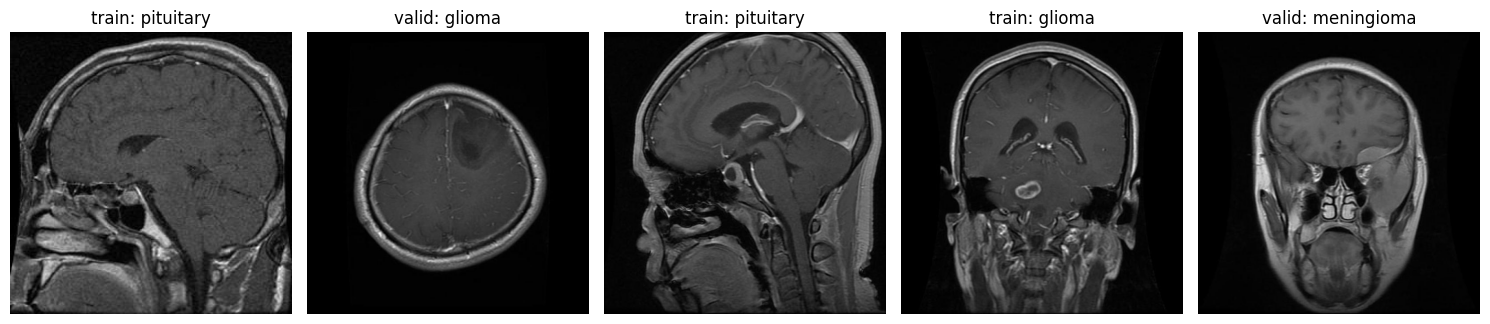

In [ ]:
rows=[]; bad=[]; annotation_tables=[]
scan_roots=partitions.items() if PREDEFINED_SPLITS else [('all',DATA_DIR)]
for split_name,split_root in scan_roots:
    for class_dir in sorted(p for p in split_root.iterdir() if p.is_dir()):
        if class_dir.name.startswith('_'): continue
        for f in class_dir.rglob('*'):
            if f.is_file() and f.suffix.lower() in EXTS:
                try:
                    with Image.open(f) as im: im.verify()
                    with Image.open(f) as im: w,h=im.size
                    rows.append({'filepath':str(f),'filename':f.name,'label':class_dir.name,'split':split_name,'width':w,'height':h,'hash':hashlib.md5(f.read_bytes()).hexdigest()})
                except Exception as e: bad.append((str(f),str(e)))
    csv_path=split_root/'_classes.csv'
    if PREDEFINED_SPLITS and csv_path.exists():
        ann=pd.read_csv(csv_path); ann.columns=[str(c).strip() for c in ann.columns]
        label_cols=[c for c in ann.columns if c.lower() in {'glioma','meningioma','no tumor','pituitary','no_tumor'}]
        if 'filename' not in ann.columns or not label_cols: raise ValueError(f'Unexpected label table format: {csv_path}')
        ann['filename']=ann.filename.astype(str).map(lambda x:Path(x).name)
        ann['csv_label']=ann[label_cols].astype(float).idxmax(axis=1).str.lower().str.replace(' ','_',regex=False)
        ann['split']=split_name; annotation_tables.append(ann[['filename','csv_label','split']])
df=pd.DataFrame(rows)
if df.empty: raise ValueError('No readable images found.')
if annotation_tables:
    annotations=pd.concat(annotation_tables,ignore_index=True)
    df=df.merge(annotations,on=['filename','split'],how='left',validate='one_to_one',indicator=True)
    missing=df['_merge'].ne('both').sum(); mismatch=(df.csv_label.notna() & (df.label!=df.csv_label)).sum()
    print('Label CSV join unmatched images:',missing,'| folder/CSV label mismatches:',mismatch)
    if missing or mismatch: raise ValueError('Resolve missing/mismatched class labels before training.')
    df=df.drop(columns=['csv_label','_merge'])
print('Readable',len(df),'unreadable',len(bad),'duplicate contents',df.hash.duplicated().sum())
print('Images by split and class:\n',pd.crosstab(df.split,df.label)); display(df[['width','height']].describe()); display(df.head())
fig,ax=plt.subplots(1,3,figsize=(15,4)); df.label.value_counts().plot.bar(ax=ax[0],title='Class counts'); df.width.hist(ax=ax[1],bins=20); ax[1].set_title('Width'); df.height.hist(ax=ax[2],bins=20); ax[2].set_title('Height'); plt.tight_layout(); plt.show()
fig,ax=plt.subplots(1,min(5,len(df)),figsize=(15,4)); ax=np.atleast_1d(ax)
for a,r in zip(ax,df.sample(min(5,len(df)),random_state=SEED).itertuples()): a.imshow(Image.open(r.filepath).convert('RGB')); a.set_title(f'{r.split}: {r.label}'); a.axis('off')
plt.tight_layout(); plt.show()

**Compare representative images across classes**
This side-by-side view helps you inspect how the labeled examples look across glioma, meningioma, no_tumor, and pituitary. It is a data-quality and visual-exploration step: note image quality, framing, intensity, and possible similarities between classes. A few examples cannot establish whether the classes are reliably distinguishable, and visual inspection here is not a medical interpretation.

INSIGHTS FROM THE OUTPUTS

1. Images by split and class
The dataset contains 2,443 images across four classes and three partitions:
Class	         Train	       Validation	       Test	     Total
Glioma	        564	           161	            80	      805
Meningioma	    358	           124	            63	      545
No tumor	      335	            99	            49	      483
Pituitary	      438	           118	            54	      610
Total	         1,695	         502	            246	     2,443

The training set contains about 69.4% of the images, validation about 20.5%, and test about 10.1%. Each class appears in all three partitions, and the class proportions are broadly similar across them. That is useful because it means the validation and test sets appear to represent the overall class mix.
The classes are not perfectly balanced. Glioma is the largest class, with 805 images; no tumor is the smallest, with 483. The largest class is about 1.7 times the size of the smallest. This is a moderate difference worth monitoring. The notebook calculates class weights to help address it during training, while the per-class metrics and confusion matrix will show whether any class is harder for the model.

2. Image dimensions
The table reports 2,443 images, with both width and height equal to 640 pixels for every image. The mean, minimum, maximum, and quartiles are all 640, and the standard deviation is zero.
This means the original images already have consistent, square dimensions. The width and height histograms each show a single concentration at 640 pixels, which agrees with the summary table. The notebook still resizes images to 224 × 224 because the models use that input size, but it does not need to handle varying source resolutions.

3. Data inventory and sample rows
The sample rows show that the inventory includes each image’s file path, filename, class label, split, dimensions, and hash. These fields help trace an image back to its source, confirm its assigned class and partition, and identify exact duplicate file contents.
The displayed sample rows have different hashes. That confirms those particular files have different contents; it does not, by itself, establish whether duplicates exist elsewhere in the dataset. The notebook’s duplicate-count output is the value to report for the complete collection.

4. Sample MRI images
The sample grid shows images from train and validation, including glioma, meningioma, and pituitary examples. The displayed scans vary in orientation and framing; for example, some are side views while others are front or cross-sectional views. That variation is useful to notice during data exploration because images may differ in more than tumor category.
This is a small random sample, not a balanced comparison: it shows pituitary and glioma more than once and does not show a no-tumor example. Use the separate one-image-per-class comparison to view all four labels side by side. These plots support image-quality and label checks; they are not clinical interpretations.

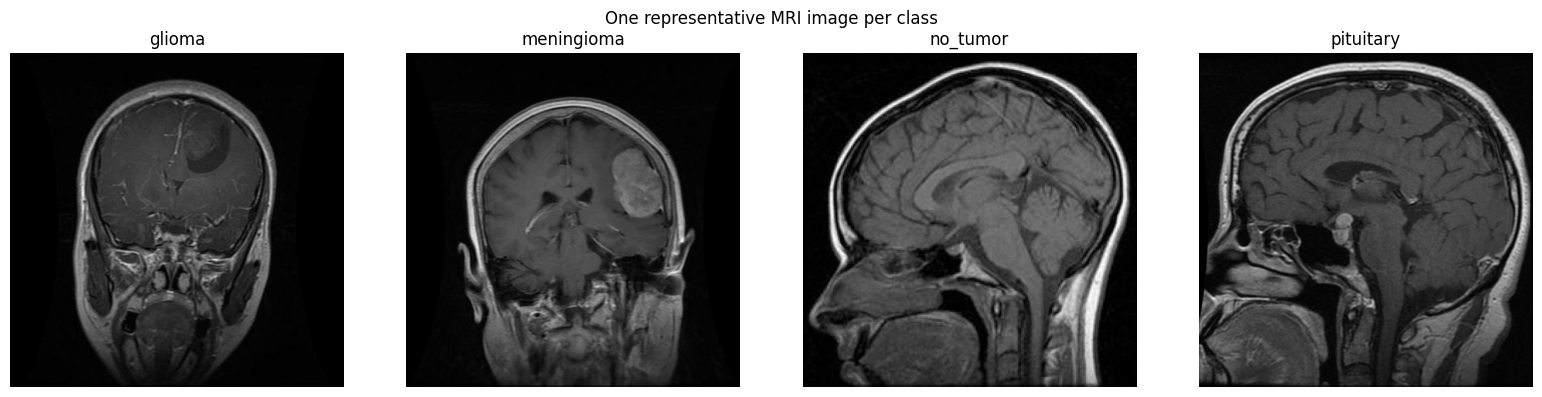

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Get class names directly from the labels in the dataframe
class_names = sorted(df["label"].dropna().unique())

fig, axes = plt.subplots(
    1, len(class_names),
    figsize=(4 * len(class_names), 4)
)
axes = np.atleast_1d(axes)

for ax, label in zip(axes, class_names):
    samples = df[df["label"] == label]

    if samples.empty:
        ax.set_title(f"{label}: no images")
        ax.axis("off")
        continue

    row = samples.sample(n=1, random_state=SEED).iloc[0]

    with Image.open(row["filepath"]) as image:
        ax.imshow(image.convert("RGB"))

    ax.set_title(label)
    ax.axis("off")

plt.suptitle("One representative MRI image per class")
plt.tight_layout()
plt.show()

**What to note**: Do the samples have consistent framing and image quality? Are some labels represented by noticeably different image sources or backgrounds? Mention concrete observations from the displayed images, but avoid claiming that a tumor can be diagnosed from this small sample. If examples appear mislabeled or corrupted, investigate the original annotations.

DETAILED INSIGHTS FROM THE OUTPUT

Detailed insights
This figure displays one MRI image from each of the four dataset classes: glioma, meningioma, no tumor, and pituitary. It provides a visual comparison of the examples supplied to the model; it does not show model predictions or prove that the labels are medically correct.
- Glioma: The sample is a front-facing scan. A darker, rounded area is visible in the upper part of the brain image.
- Meningioma: This is also front-facing, with a bright area visible on one side of the brain.
- No tumor: This example is a side-facing scan. No obvious mass is apparent in this particular image.
- Pituitary: This is a side-facing scan, with the region around the pituitary visible near the center of the image.
The samples are grayscale and have dark backgrounds, but they differ in orientation and framing. In this figure, the glioma and meningioma examples are front-facing, while the no-tumor and pituitary examples are side-facing. If that pattern also occurs across many images, the model might learn scan orientation or image-source cues that correlate with a class, instead of relying mainly on relevant image features. Check more samples and the class distributions by orientation before drawing conclusions.
Because the plot shows only one randomly selected image per class, it cannot represent all variation in that class. It also cannot establish that the classes can reliably be distinguished by sight. Use this comparison for data exploration and quality review; rely on held-out evaluation metrics and qualified medical expertise for any further interpretation

**Reading the dataset graphs**
Class counts: The bar chart checks whether some tumor categories have many fewer examples. Large differences can bias learning toward frequent classes; class weighting helps, but more representative data may still be needed. Use the actual bars from your run to describe which categories are largest or smallest.
Image width and height: The histograms show source resolution variation. They help confirm that resizing is necessary and reveal unusually small or large inputs that may merit image-quality review. Resizing to 224 × 224 standardizes model input; inspect any unusual distribution before assuming all images are comparable.
Example MRI images: The sample grid is a visual label and quality check. Confirm that images are readable, labels appear plausible, and obvious artifacts or mislabeled examples are investigated. The displayed examples are a sample, so they do not establish the quality of the entire dataset.
The provided README describes 2,443 images in four classes, with 1,695 train, 502 validation, and 246 test images. The three archives include _classes.csv; this notebook joins those labels to image filenames and checks agreement with folder labels. The split counts printed by Colab are the values to report after unreadable files and exact duplicates are handled.

**Data cleaning, wrangling, and optional metadata merge**
This section prepares a trustworthy image inventory before model splitting. It removes exact duplicate image contents while retaining one file per duplicate group, creates useful image-level fields (aspect ratio, mean brightness, and contrast), and can merge optional CSV metadata. The class label remains the name of the image's parent class folder; metadata joins do not silently replace it. If your dataset has no separate metadata CSV, leave METADATA_CSV as None and the merge is skipped.

In [ ]:
# Cleaning: prioritize train copies when exact image contents occur across partitions,
# so duplicate content cannot leak from training into validation/test.
before=len(df)
if PREDEFINED_SPLITS:
    split_priority={'train':0,'valid':1,'test':2}
    df['_priority']=df.split.map(split_priority)
    df=df.sort_values(['_priority','filepath']).drop_duplicates(subset='hash',keep='first').drop(columns='_priority')
else:
    df=df.sort_values('filepath').drop_duplicates(subset='hash',keep='first')
df=df.reset_index(drop=True)
print('Exact duplicate files removed:',before-len(df))
# Wrangling: derive image-level attributes for quality inspection; these are not CNN inputs.
def image_features(path):
    with Image.open(path) as im:
        gray=np.asarray(im.convert('L'),dtype=np.float32)/255.; width,height=im.size
    return width,height,width/height,float(gray.mean()),float(gray.std())
features=np.array([image_features(p) for p in df.filepath])
df[['width','height','aspect_ratio','brightness_mean','contrast_std']]=features
print('Clean image count:',len(df),'classes:',df.label.nunique())
display(df[['label','width','height','aspect_ratio','brightness_mean','contrast_std']].describe(include='all'))
# Optional extra metadata merge: CSV must contain one unique 'filename' per image.
# The supplied archives already include _classes.csv, which was merged and validated above.
METADATA_CSV=None
if METADATA_CSV:
    metadata=pd.read_csv(METADATA_CSV); metadata['filename']=metadata.filename.astype(str).map(lambda x:Path(x).name)
    if metadata.filename.duplicated().any(): raise ValueError('Metadata filenames must be unique before merging.')
    df=df.merge(metadata,on='filename',how='left',validate='many_to_one',indicator=True)
    print('Extra metadata merge status:\n',df['_merge'].value_counts()); df=df.drop(columns='_merge')
else: print('No additional metadata CSV configured.')

Exact duplicate files removed: 0
Clean image count: 2443 classes: 4


,label,width,height,aspect_ratio,brightness_mean,contrast_std
count,2443,2443.0,2443.0,2443.0,2443.000000,2443.000000
unique,4,NaN,NaN,NaN,NaN,NaN
top,glioma,NaN,NaN,NaN,NaN,NaN
freq,805,NaN,NaN,NaN,NaN,NaN
mean,NaN,640.0,640.0,1.0,0.171634,0.173204
std,NaN,0.0,0.0,0.0,0.073049,0.044839
min,NaN,640.0,640.0,1.0,0.038269,0.087158
25%,NaN,640.0,640.0,1.0,0.115820,0.145147
50%,NaN,640.0,640.0,1.0,0.157028,0.163329
75%,NaN,640.0,640.0,1.0,0.208210,0.188079


No additional metadata CSV configured.


**Data wrangling visualizations: brightness and contrast**
The brightness histogram summarizes average grayscale intensity per image; the contrast histogram summarizes within-image intensity spread. These help identify broad acquisition or preprocessing differences and unusually dark, bright, or low-contrast files for review. A peak or outlier is a prompt to inspect images, not automatic evidence that an image is invalid.

**Why we calculate brightness and contrast**

Each MRI is converted to grayscale so the notebook can calculate two simple image-level measurements:
- Mean brightness: the average pixel intensity, scaled from 0 (black) to 1 (white). It summarizes how light or dark the whole image is.
- Contrast: the standard deviation of pixel intensities within an image. A larger value means pixel intensities are more spread out; a smaller value means they are more similar.
These measurements help us inspect general image variation. For example, very dark, bright, or low-contrast files may be worth checking for image-quality or preprocessing issues. They are not used here to diagnose tumors or as extra CNN inputs. Black borders and background area can affect both measurements, so unusual values are prompts for review rather than proof an image is invalid.

**Why use histograms**


Brightness and contrast are continuous numeric measurements, so a histogram is a useful way to show their distributions. It groups values into ranges, or bins:
- The horizontal axis shows a brightness or contrast range.
- The vertical axis shows how many images fall within that range.
A histogram makes it easy to see where most images cluster, how widely values vary, whether a distribution is skewed or has multiple peaks, and whether some values are unusually far from the rest. A bar chart is better suited to comparing named categories, such as tumor classes; a histogram is better for examining the distribution of numeric measurements.
In your earlier summary, the average per-image brightness was about 0.172 and the average contrast measure was about 0.173. The histograms show how individual images are distributed around those averages.

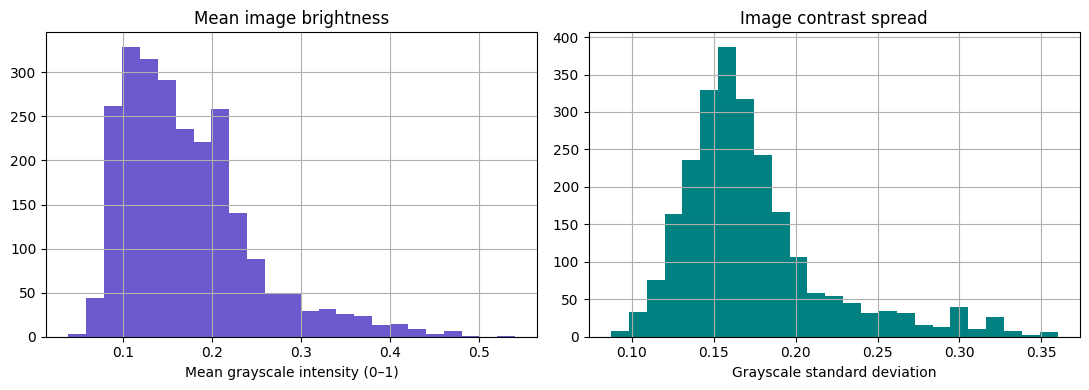

In [ ]:
fig,ax=plt.subplots(1,2,figsize=(11,4))
df.brightness_mean.hist(ax=ax[0],bins=25,color='slateblue'); ax[0].set_title('Mean image brightness'); ax[0].set_xlabel('Mean grayscale intensity (0–1)')
df.contrast_std.hist(ax=ax[1],bins=25,color='teal'); ax[1].set_title('Image contrast spread'); ax[1].set_xlabel('Grayscale standard deviation')
plt.tight_layout(); plt.show()

**Insights from the brightness and contrast histograms**
Mean image brightness: Most images cluster between roughly 0.08 and 0.22 on the 0–1 grayscale scale, with the highest concentration around 0.10–0.15. The distribution has a long right tail, extending to about 0.54, meaning a smaller number of images have much higher average brightness. This shows that image intensity varies across the dataset; it does not indicate that bright images are invalid.
Image contrast spread: Most images have contrast values around 0.13–0.20, with the histogram peaking near 0.15–0.18. A smaller group extends above 0.25, up to about 0.36, indicating images with greater intensity variation.
Overall interpretation: Both histograms are right-skewed: most images have relatively low-to-moderate brightness and contrast, while fewer images have higher values. These variations may reflect differences in scan content, framing, or acquisition. Since black background areas affect both measurements, the unusually bright or high-contrast images should be visually checked before considering any preprocessing changes.

**Reading the brightness and contrast graphs**
Look for wide spreads, multiple peaks, or isolated extremes. They may reflect acquisition variation, image borders, or preprocessing differences. Review representative files before changing or excluding data, since unusual intensity can be genuine. These descriptive measurements are calculated after cleaning and are not used as labels or fed into the CNN.

**Stratified 70/15/15 split and data pipeline**
Augmentation is applied only while training. Images are resized and normalized to 0–1. Stratification maintains class representation in each split. The dataset is already divided into training, validation, and test sets, so these partitions are preserved rather than combined and randomly split. Training data is used to update the model’s weights. Validation data is used to monitor learning and compare models during development. The test set is held back for the final evaluation.
Images are decoded, resized from 640 × 640 to 224 × 224 pixels, and normalized by dividing pixel values by 255, placing them in the 0–1 range. This gives the models a consistent input shape and scale. Random augmentation and shuffling are applied only to training data; validation and test images remain unchanged so evaluation reflects the original examples.
Stratification is used only as a fallback when a dataset does not already provide splits. It creates subsets that retain similar class proportions, reducing the chance that a class is underrepresented in one subset.

In [ ]:
class_names=sorted(df.label.unique()); n=len(class_names)
if n<2: raise ValueError('Need at least two classes.')
if PREDEFINED_SPLITS:
    train_df=df[df.split=='train'].copy(); val_df=df[df.split=='valid'].copy(); test_df=df[df.split=='test'].copy()
    if min(len(train_df),len(val_df),len(test_df))==0: raise ValueError('A provided split has no readable images after cleaning.')
else:
    train_df,tmp=train_test_split(df,test_size=.30,stratify=df.label,random_state=SEED)
    val_df,test_df=train_test_split(tmp,test_size=.50,stratify=tmp.label,random_state=SEED)
print('Classes:',class_names,'| train:',len(train_df),'validation:',len(val_df),'test:',len(test_df))
print('Split class counts:\n',pd.concat([train_df.assign(partition='train'),val_df.assign(partition='valid'),test_df.assign(partition='test')]).groupby(['partition','label']).size().unstack(fill_value=0))
label_id={c:i for i,c in enumerate(class_names)}
def dataset(frame,training=False):
    ds=tf.data.Dataset.from_tensor_slices((frame.filepath.to_numpy(),frame.label.map(label_id).to_numpy(np.int32)))
    def load(path,y):
        x=tf.io.decode_image(tf.io.read_file(path),channels=3,expand_animations=False); x.set_shape([None,None,3])
        return tf.image.resize(x,IMG_SIZE)/255.,y
    ds=ds.map(load,num_parallel_calls=tf.data.AUTOTUNE)
    if training: ds=ds.shuffle(len(frame),seed=SEED)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
train_ds=dataset(train_df,True); val_ds=dataset(val_df); test_ds=dataset(test_df)
ids=np.arange(n); w=compute_class_weight('balanced',classes=ids,y=train_df.label.map(label_id)); class_weight=dict(zip(ids,w))
print('class weights',class_weight)

Classes: ['glioma', 'meningioma', 'no_tumor', 'pituitary'] | train: 1695 validation: 502 test: 246
Split class counts:
 label      glioma  meningioma  no_tumor  pituitary
partition                                         
test           80          63        49         54
train         564         358       335        438
valid         161         124        99        118
class weights {np.int64(0): np.float64(0.7513297872340425), np.int64(1): np.float64(1.183659217877095), np.int64(2): np.float64(1.2649253731343284), np.int64(3): np.float64(0.9674657534246576)}


DETAILED INSIGHTS

The output confirms that the notebook preserved the dataset’s original partitions: 1,695 training images, 502 validation images, and 246 test images, for 2,443 images total. All four categories—glioma, meningioma, no tumor, and pituitary—appear in each partition, and their proportions are broadly similar across the splits. This supports using the validation set to compare models and keeping the test set for final evaluation.

The data pipeline maps class names to integer labels, decodes each image as a three-channel image, resizes it from 640 × 640 to 224 × 224 pixels, and scales its pixel values to the 0–1 range. It shuffles the training data only, then batches and prefetches images to make data delivery more efficient during training. Validation and test data remain unshuffled and unaugmented so their evaluation is consistent.

The training classes have different numbers of images: glioma has the most, with 564, while no tumor has the fewest, with 335. To account for this imbalance, the notebook assigns a class weight to each category. No tumor receives the largest weight, approximately 1.265, and glioma receives the smallest, approximately 0.751. This means errors on less frequent classes contribute more to the training loss, while the class with more examples contributes slightly less per image. The weights change how the model learns; they do not add, remove, or duplicate images.

**Custom CNN**

A custom CNN is a CNN whose architecture is designed and built for a particular project, rather than using a complete pretrained model. In this project, the custom CNN learns its filters from the brain MRI training images. It provides a baseline for comparison with MobileNetV2, which starts with features learned from a much larger ImageNet dataset.
The custom CNN architecture follows this sequence:
1. Input layer: Receives each MRI image as a 224 × 224, three-channel tensor.
2. Data augmentation: Applies random horizontal flips, small rotations, zooms, and translations during training to expose the model to modest image variation.
3. Convolution blocks: Three blocks use 32, 64, and 128 filters. Each block applies a convolution to detect image features, batch normalization to stabilize learning, a ReLU activation to introduce nonlinearity, max pooling to reduce spatial size, and dropout to reduce overfitting.
4. Deeper convolution layer: A 256-filter convolution learns more complex combinations of the earlier features.
5. Global average pooling: Summarizes each feature map into a single value, reducing the number of parameters compared with flattening the full feature maps.
6. Dense layer: A 128-unit layer combines the extracted features for classification.
7. Dropout: Randomly deactivates some units during training to help the model avoid relying too heavily on particular features.
8. Output layer: A four-unit softmax layer produces a score for glioma, meningioma, no tumor, and pituitary. The scores sum to 1 and represent the model’s relative predictions.
The model is trained with the Adam optimizer and sparse categorical cross-entropy loss, which is suitable when each image has one integer class label. Early stopping, learning-rate reduction, and model checkpointing help manage training and preserve a strong validation checkpoint.

In [ ]:
# Augment training images only
augment = keras.Sequential(
    [
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.06),
        layers.RandomZoom(0.10),
        layers.RandomTranslation(0.08, 0.08),
    ],
    name="augmentation",
)

def make_cnn():
    inputs = keras.Input(shape=(*IMG_SIZE, 3))
    x = augment(inputs)

    for filters in (32, 64, 128):
        x = layers.Conv2D(
            filters, kernel_size=3, padding="same", use_bias=False
        )(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        x = layers.MaxPooling2D()(x)
        x = layers.Dropout(0.20)(x)

    x = layers.Conv2D(256, 3, padding="same", activation="relu")(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.40)(x)
    outputs = layers.Dense(n, activation="softmax")(x)

    model = keras.Model(inputs, outputs, name="custom_cnn")
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model

def callbacks(name):
    return [
        keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=4, restore_best_weights=True
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.3, patience=2
        ),
        keras.callbacks.ModelCheckpoint(
            filepath=str(OUT / f"{name}.keras"),
            monitor="val_loss",
            save_best_only=True,
        ),
    ]

cnn = make_cnn()
cnn.summary()

history_cnn = cnn.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    class_weight=class_weight,
    callbacks=callbacks("best_cnn"),
)

Model: "custom_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 422,500 (1.61 MB)

 Trainable params: 422,052 (1.61 MB)

 Non-trainable params: 448 (1.75 KB)

Epoch 1/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 262s 5s/step - accuracy: 0.5192 - loss: 1.2200 - val_accuracy: 0.2351 - val_loss: 1.5330 - learning_rate: 0.0010
Epoch 2/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 265s 5s/step - accuracy: 0.6177 - loss: 0.9687 - val_accuracy: 0.5080 - val_loss: 1.5616 - learning_rate: 0.0010
Epoch 3/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 311s 6s/step - accuracy: 0.6667 - loss: 0.9096 - val_accuracy: 0.3307 - val_loss: 1.6223 - learning_rate: 0.0010
Epoch 4/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 245s 5s/step - accuracy: 0.6855 - loss: 0.8596 - val_accuracy: 0.3347 - val_loss: 1.8017 - learning_rate: 3.0000e-04
Epoch 5/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 267s 5s/step - accuracy: 0.6985 - loss: 0.8187 - val_accuracy: 0.3386 - val_loss: 1.8617 - learning_rate: 3.0000e-04


**Compare original and augmented training images**
Augmentation creates altered views of training images to help the model handle modest variation. This grid lets you verify that the flips, rotations, zooms, and shifts preserve a recognizable MRI image and do not crop away important content. Augmentation is applied during training only; validation and test images remain unchanged.

INSIGHTS FROM THE OUTPUT

The model summary shows the final stages of the custom CNN. After the convolution and pooling layers, the feature map is reduced to 28 × 28 × 128. A 256-filter convolution then produces 28 × 28 × 256 features. Global average pooling reduces these feature maps to 256 values; a 128-unit dense layer processes them, and the final dense layer has 4 outputs, one for each class.
The model has 422,500 parameters, of which 422,052 are trainable and 448 are non-trainable. This is a relatively compact model compared with many large image networks. The output shape (None, 4) means it produces four class scores for each image; None represents a batch size that can vary.
The first five training epochs show a concerning gap between training and validation performance. Training accuracy increases from 51.9% to 69.9%, while training loss decreases from 1.220 to 0.819. This means the model is learning the training images. Validation accuracy, however, fluctuates—23.5%, 50.8%, 33.1%, 33.5%, and 33.9%—and validation loss rises from 1.533 to 1.861. In particular, the rise in validation loss while training loss falls suggests that the model may be overfitting or that its predictions on validation images are becoming less reliable. The fluctuating validation accuracy also means that these early results are not stable enough to select a model.
These are only the first five epochs, not the final evaluation. The configured early-stopping callback should stop training if validation loss fails to improve and restore the best weights. Check which epoch had the lowest validation loss, then review the full training curves and per-class confusion matrix. If the pattern continues, verify the label mapping and validation images, inspect class-specific errors, and consider reducing model complexity or augmentation strength.

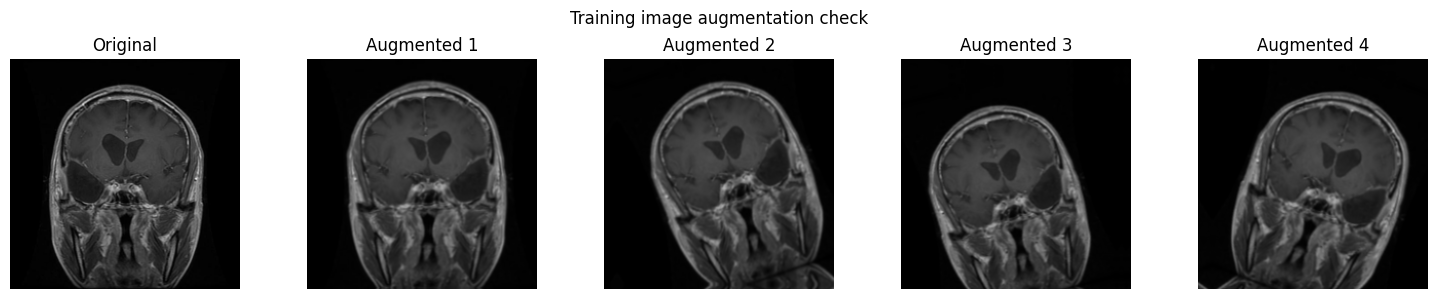

In [ ]:
# Display an original training image and several random augmented versions.
raw_path=train_df.iloc[0].filepath
with Image.open(raw_path) as im: original=np.asarray(im.convert('RGB').resize(IMG_SIZE),dtype=np.float32)/255.0
views=[original]+[augment(tf.convert_to_tensor(original[None,...]),training=True)[0].numpy() for _ in range(4)]
fig,axes=plt.subplots(1,len(views),figsize=(15,3))
for i,(ax,img) in enumerate(zip(axes,views)):
    ax.imshow(np.clip(img,0,1)); ax.set_title('Original' if i==0 else f'Augmented {i}'); ax.axis('off')
plt.suptitle('Training image augmentation check'); plt.tight_layout(); plt.show()

**What to note:** Confirm that augmented examples still show the same overall anatomy and useful image content. If a transformed view appears excessively cropped or unnatural, reduce augmentation strength. A mirrored or rotated view is a training transformation, not a new independent medical case.

INSIGHT FROM THE OUTPUT

This figure checks whether the training augmentation produces reasonable variations of an MRI image. It shows one original scan and four randomly transformed versions of that same scan. They remain broadly recognizable, while their orientation, position, and apparent framing vary slightly.
The model’s augmentation pipeline can apply horizontal flips, small rotations, zooms, and translations. These transformations are generated randomly during training, so the examples may look different each time the cell runs. They are not four new independent images; each retains the original image’s class label.
In this figure, the brain remains visible in all four transformed examples. Some versions shift or rotate the scan enough that edges and lower portions are closer to the image boundary. Check that transformations don’t crop useful content. Horizontal flipping can also change left-right orientation, so it should only be used if that change is appropriate for the project’s classification goal.

MobileNetV2 transfer learning and fine tuning

## Transfer learning

**Transfer learning** means reusing a model that has already learned useful features from one dataset and adapting it to a new task. Here, **MobileNetV2** is initialized with weights learned from ImageNet, a large collection of natural images. Its earlier layers have learned general visual patterns such as edges, textures, and shapes.

For this project, the original ImageNet classification head is removed and replaced with a new output layer for the four MRI classes: glioma, meningioma, no tumor, and pituitary. At first, the pretrained MobileNetV2 layers are frozen, so their weights stay unchanged while the new classification head learns from the MRI training images.

**Why use it:** Transfer learning can provide a useful starting point when the target dataset is smaller than the dataset used to train a model from scratch. It may reduce training time and help the model learn, though success is not guaranteed: ImageNet contains natural images, not MRI scans.

## Fine-tuning

**Fine-tuning** is a later stage of transfer learning. After the new classification head has trained, selected layers of the pretrained model are unfrozen and updated using the target dataset. In this notebook, the last 30 MobileNetV2 layers are made trainable, while earlier layers and batch-normalization layers remain frozen. A much smaller learning rate is used so the pretrained weights change gradually.

**Why use it:** The new head learns how to map features to the four MRI labels. Fine-tuning then lets some higher-level visual features adapt to the MRI images. It may improve performance, but it can also overfit or reduce useful pretrained features, so its validation results should be compared with the initial transfer-learning model.

### Key difference

Transfer learning first reuses the pretrained feature extractor while training a new classifier. Fine-tuning continues from there by carefully updating selected pretrained layers as well. The project compares their validation performance to see whether those extra updates help on this dataset.

In [ ]:
# Check the training batch and label range first
images, labels = next(iter(train_ds))
print("Image batch:", images.shape, images.dtype)
print("Label batch:", labels.shape, labels.dtype)
print("Labels in batch:", tf.unique(tf.reshape(labels, [-1])).y.numpy())
print("Model classes:", n)

# Build MobileNetV2 transfer-learning model
def make_tl():
    inputs = keras.Input(shape=(*IMG_SIZE, 3))
    x = augment(inputs)

    # Input images are scaled to [0, 1]; MobileNetV2 preprocessing expects [0, 255].
    x = layers.Lambda(
        lambda image: tf.keras.applications.mobilenet_v2.preprocess_input(image * 255.0)
    )(x)

    base_model = keras.applications.MobileNetV2(
        include_top=False,
        weights="imagenet",
        input_shape=(*IMG_SIZE, 3),
    )
    base_model.trainable = False

    x = base_model(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.35)(x)
    outputs = layers.Dense(n, activation="softmax")(x)

    model = keras.Model(inputs, outputs, name="mobilenetv2")
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model, base_model

tl, base = make_tl()
tl.summary()

history_tl = tl.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    class_weight=class_weight,
    callbacks=callbacks("best_mobilenet"),
)

Image batch: (32, 224, 224, 3) <dtype: 'float32'>
Label batch: (32,) <dtype: 'int32'>
Labels in batch: [3 2 0 1]
Model classes: 4


Model: "mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda_1 (Lambda)               │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 89s 2s/step - accuracy: 0.5652 - loss: 1.0902 - val_accuracy: 0.7032 - val_loss: 0.7121 - learning_rate: 0.0010
Epoch 2/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 77s 1s/step - accuracy: 0.7611 - loss: 0.6231 - val_accuracy: 0.7311 - val_loss: 0.6579 - learning_rate: 0.0010
Epoch 3/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 80s 1s/step - accuracy: 0.8159 - loss: 0.5154 - val_accuracy: 0.7430 - val_loss: 0.6363 - learning_rate: 0.0010
Epoch 4/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 85s 1s/step - accuracy: 0.8383 - loss: 0.4544 - val_accuracy: 0.7789 - val_loss: 0.5552 - learning_rate: 0.0010
Epoch 5/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 74s 1s/step - accuracy: 0.8431 - loss: 0.4475 - val_accuracy: 0.7570 - val_loss: 0.6305 - learning_rate: 0.0010
Epoch 6/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 83s 1s/step - accuracy: 0.8460 - loss: 0.4091 - val_accuracy: 0.7689 - val_loss: 0.6078 - learning_rate: 0.0010
Epoch 7/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 67s 1s/step - accuracy: 0.8625 - loss: 0.3714 - val_accuracy: 

DETAILED INSIGHT OF OUTPUT

Detailed insight
This output shows the initial MobileNetV2 transfer-learning stage. The model has about 2.26 million parameters, but only 5,124 are trainable. Most of MobileNetV2 is frozen, so training updates mainly the new four-class classification head. The output shape (None, 4) means the model produces a score for each of the four MRI categories for every image in a batch.
Training performance improves steadily through the displayed epochs: accuracy rises from 56.5% at epoch 1 to 88.6% at epoch 12, while training loss falls from 1.090 to 0.329. This indicates that the model is learning the training examples.
Validation performance improves overall but fluctuates. Validation accuracy rises from 70.3% to a peak of 81.5% at epoch 8, then varies between about 76.3% and 79.5% in the later displayed epochs. Validation loss reaches its lowest displayed value, 0.5219, at epoch 8, then increases. The growing difference between training and validation performance suggests the model may be starting to overfit: it continues improving on training data, but that improvement does not consistently carry over to validation data.
The learning rate falls from 0.001 to 0.0003 at epoch 7, and then to 0.00009 at epoch 11. This is the learning-rate scheduler responding to a plateau in validation loss. Because validation loss does not improve after epoch 8, the early-stopping callback is expected to stop training after the configured patience period and restore the best weights. The checkpoint callback also saves the model with the best validation loss, which in the displayed output is epoch 8.
These are validation results, not the final test results. They do not establish how well the model performs on the held-out test set. Review the final test metrics and confusion matrix before comparing this model with the custom CNN or the fine-tuned MobileNetV2

In [ ]:
# Fine-tune only the last 30 MobileNetV2 layers.
base.trainable = True

for layer in base.layers[:-30]:
    layer.trainable = False

# Keep batch-normalization layers frozen for stable fine-tuning.
for layer in base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

tl.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

history_finetune = tl.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    class_weight=class_weight,
    callbacks=callbacks("best_mobilenet_finetuned"),
)

Epoch 1/5
53/53 ━━━━━━━━━━━━━━━━━━━━ 91s 1s/step - accuracy: 0.8808 - loss: 0.3541 - val_accuracy: 0.7948 - val_loss: 0.5960 - learning_rate: 1.0000e-05
Epoch 2/5
53/53 ━━━━━━━━━━━━━━━━━━━━ 78s 1s/step - accuracy: 0.8879 - loss: 0.2992 - val_accuracy: 0.8028 - val_loss: 0.5626 - learning_rate: 1.0000e-05
Epoch 3/5
53/53 ━━━━━━━━━━━━━━━━━━━━ 82s 1s/step - accuracy: 0.9091 - loss: 0.2843 - val_accuracy: 0.8008 - val_loss: 0.6059 - learning_rate: 1.0000e-05
Epoch 4/5
53/53 ━━━━━━━━━━━━━━━━━━━━ 90s 2s/step - accuracy: 0.9068 - loss: 0.2689 - val_accuracy: 0.8048 - val_loss: 0.6029 - learning_rate: 1.0000e-05
Epoch 5/5
53/53 ━━━━━━━━━━━━━━━━━━━━ 86s 2s/step - accuracy: 0.8979 - loss: 0.2658 - val_accuracy: 0.8267 - val_loss: 0.5108 - learning_rate: 3.0000e-06


DETAILED INSIGHT OF OUTPUT

This output shows the **fine-tuning stage** of MobileNetV2. The model starts with weights learned during the initial transfer-learning stage, then updates selected upper layers using a small learning rate of **0.00001**. This lets some of the pretrained features adapt to the MRI images gradually.

Across the five fine-tuning epochs, training accuracy stays around **88.0%–91.0%**, and training loss decreases from **0.3541 to 0.2658**. This indicates that the model continues to fit the training data. Validation accuracy improves from **79.5% at epoch 1** to **82.7% at epoch 5**, while validation loss reaches its lowest value, **0.5108**, in the final epoch. Validation results fluctuate slightly in the middle epochs, but the final epoch is the best shown by both validation accuracy and validation loss.

Compared with the initial MobileNetV2 training output you shared, fine-tuning improves the best validation accuracy from approximately **81.5% to 82.7%**, a gain of about **1.2 percentage points**. The best validation loss decreases from approximately **0.5219 to 0.5108**. This is a modest improvement, not proof that the model will perform better on unseen data. The training accuracy remains about seven percentage points higher than validation accuracy at the final epoch, so some generalization gap remains.

The learning rate decreases to **0.000003** at epoch 5, allowing smaller weight updates. Since this run was limited to five epochs, the output alone does not show whether further fine-tuning would help. Use the validation results to compare candidate models, then report performance on the separate held-out test set before making a final conclusion.

**Training history plots**

Training history plots are graphs that show how a model’s performance changes during training. The horizontal axis represents epochs—complete passes through the training dataset. The vertical axis shows a metric recorded after each epoch. The notebook plots accuracy and loss, with separate curves for the training set and validation set.
Training accuracy is the proportion of training images the model classifies correctly. Validation accuracy measures accuracy on a separate set of images the model does not use to update its weights. Comparing them helps show whether learning on the training data is also carrying over to unseen examples.
Training loss measures the model’s prediction error on the training images. Validation loss measures that error on the validation images. The model trains to reduce loss; accuracy and loss together give a fuller picture because accuracy counts correct classifications, while loss also reflects how confident or uncertain the predictions are.
These plots help identify common training patterns. If training and validation accuracy rise together and both losses fall, the model is learning patterns that may generalize. If training accuracy keeps rising while validation accuracy stalls or falls—and validation loss increases—the model may be overfitting. If both sets of metrics remain poor, the model may not be learning effectively. These are signs to investigate, not conclusions about clinical performance.

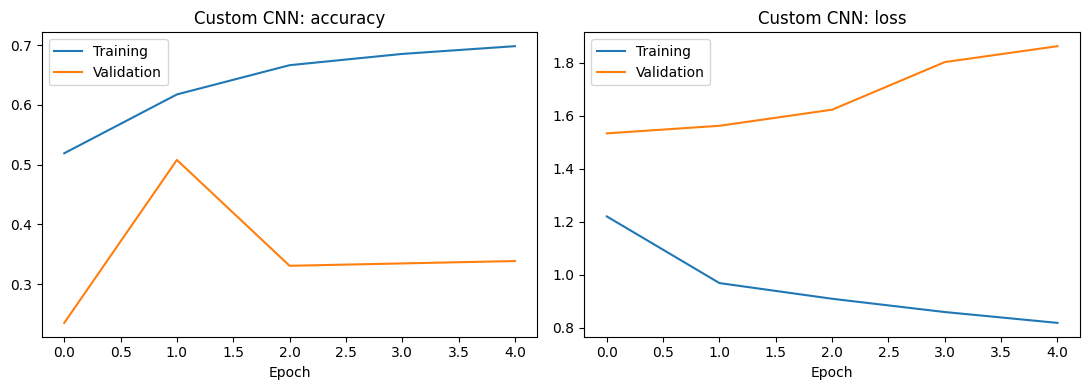

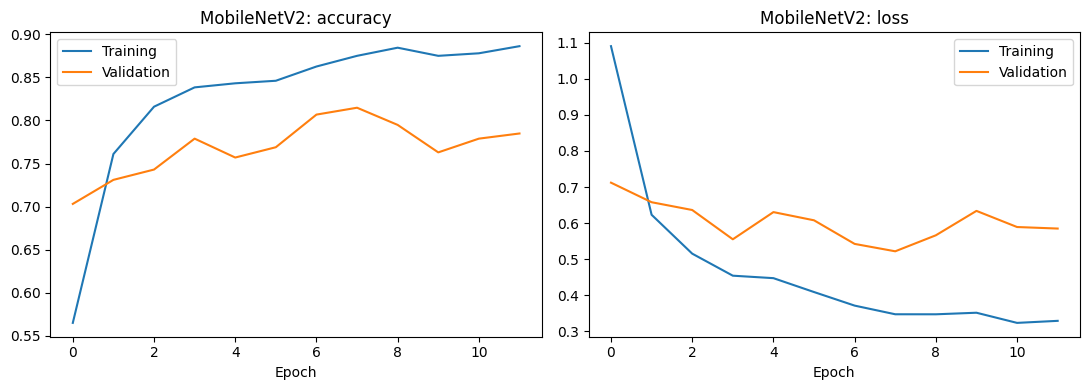

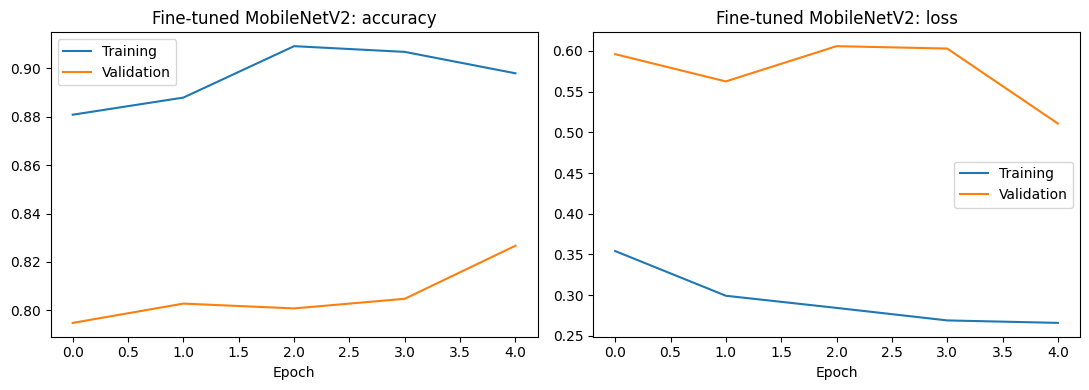

In [ ]:
import matplotlib.pyplot as plt

def plot_history(history, name):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))

    for ax, metric in zip(axes, ["accuracy", "loss"]):
        ax.plot(history.history[metric], label="Training")
        ax.plot(history.history[f"val_{metric}"], label="Validation")
        ax.set_title(f"{name}: {metric}")
        ax.set_xlabel("Epoch")
        ax.legend()

    plt.tight_layout()
    plt.show()

# Accept either variable names used in the training cells
histories = [
    ("Custom CNN", globals().get("h_cnn", globals().get("history_cnn"))),
    ("MobileNetV2", globals().get("h_tl", globals().get("history_tl"))),
    ("Fine-tuned MobileNetV2", globals().get("h_ft", globals().get("history_finetune"))),
]

for name, history in histories:
    if history is None:
        print(f"{name} history is missing. Run its training cell first.")
    else:
        plot_history(history, name)

**How to read these plots**

In each pair, the left chart shows accuracy and the right chart shows loss. Blue is the training set; orange is the validation set. The horizontal axis counts epochs, but it starts at 0 on the plot, so tick 0 represents the first epoch. Training curves show how well the model fits training images; validation curves show how it performs on images not used to update its weights.

**Custom CNN**

Training accuracy increases from about 52% to 70%, while training loss decreases from about 1.22 to 0.82. The CNN is learning the training examples.
Validation performance is much weaker and unstable. Validation accuracy starts around 24%, rises to about 51% at the second epoch, then drops and stays near 33–34%. Meanwhile, validation loss increases from about 1.53 to 1.86. The widening gap between the training and validation curves indicates poor generalization and likely overfitting: improvement on the training images is not carrying over to validation images.
The best validation accuracy and lowest validation loss occur at different epochs: validation accuracy peaks at the second epoch, while validation loss is lowest at the first. Since the callbacks monitor validation loss, the saved checkpoint is chosen based on loss, not on the highest accuracy. The custom CNN’s final quality should therefore be judged using the selected checkpoint’s evaluation and class-wise results.

**MobileNetV2**

Training accuracy rises from about 57% to 89%, and training loss falls from about 1.09 to 0.33, showing strong improvement on the training set.
Validation accuracy improves from about 70%, peaks near 81.5% at roughly the eighth epoch, and then fluctuates around 76–80%. Validation loss reaches its minimum near 0.52 at about the same point, then rises. This suggests MobileNetV2 learns useful patterns and generalizes better than the custom CNN, but starts to overfit after its best validation point. Early stopping and checkpointing are intended to retain the epoch with the best validation loss.

**Fine-tuned MobileNetV2**

During fine-tuning, training accuracy stays near 88–91% and training loss decreases from about 0.35 to 0.27. Validation accuracy begins around 79.5% and reaches about 82.7% in the last epoch. Validation loss also reaches its lowest plotted value, about 0.51, in that final epoch.
Compared with the best initial MobileNetV2 validation point—about 81.5% accuracy and 0.52 loss—the fine-tuned version improves by approximately 1.2 percentage points in accuracy and reduces validation loss slightly. This is a modest improvement. A training-to-validation gap remains, so the model should be checked on the held-out test set before drawing conclusions.

**Overall interpretation**

The plots suggest the custom CNN struggles to generalize, while MobileNetV2 performs better on validation data. Fine-tuning gives a small additional validation improvement in the results shown. These are validation results, not final test performance; the test set’s metrics and confusion matrix are needed for the final comparison. Also, each plot has its own vertical scale, so compare the reported metric values rather than judging performance only by the visual steepness of the lines.

**Reading the training graphs**
Each model has an accuracy plot and a loss plot, with separate training and validation curves. These charts show whether learning is progressing and whether the model begins to overfit. Training performance that improves while validation performance stalls or worsens can indicate overfitting; close curves that improve together are more consistent with useful generalization. Early stopping and learning-rate reduction respond to validation loss. Describe the pattern you observe for each model after running the notebook.

**Evaluation and comparison**

**Evaluation and comparison** is the stage where we measure how well each trained model classifies MRI images and compare their strengths and weaknesses. The project evaluates the custom CNN and MobileNetV2 using the validation data first. The validation set helps select a candidate model; the separate test set is then used to estimate how well that selected model performs on data it has not seen during training or model selection.

**Accuracy** is the proportion of all images classified correctly. It is easy to interpret, but can hide weak performance on a less frequent class. Precision measures, for a class, what proportion of images predicted as that class truly belong to it.

 **Recall** measures what proportion of the actual images in a class the model successfully identifies. F1-score combines precision and recall using their harmonic mean, so it is useful when both types of error matter.


The notebook reports weighted metrics and macro F1. A weighted score calculates a metric for each class and averages the scores while giving larger classes more influence according to their image counts. Macro F1 averages the class F1-scores equally, so a smaller class matters as much as a larger one. Comparing both helps reveal whether a model performs consistently across categories or mainly benefits from the more common classes.


Per-class results show precision, recall, and F1 separately for glioma, meningioma, no tumor, and pituitary. They help identify categories where the model makes more mistakes. The confusion matrix provides another view: rows represent actual classes, columns represent predicted classes, diagonal values are correct predictions, and off-diagonal values show which classes are confused with one another.


In this notebook, the model is selected using validation macro F1, giving each class equal importance during selection. Its performance is then reported on the held-out test set. The test results should not be used to repeatedly adjust or reselect the model, because doing so would make the test set part of the model-selection process and weaken its value as an independent evaluation.

CNN validation accuracy 0.2350597609561753 weighted P/R/F1 0.05525309122077428 0.2350597609561753 0.08947436062202802 macro F1 0.09516129032258064
              precision    recall  f1-score   support

      glioma       0.00      0.00      0.00       161
  meningioma       0.00      0.00      0.00       124
    no_tumor       0.00      0.00      0.00        99
   pituitary       0.24      1.00      0.38       118

    accuracy                           0.24       502
   macro avg       0.06      0.25      0.10       502
weighted avg       0.06      0.24      0.09       502



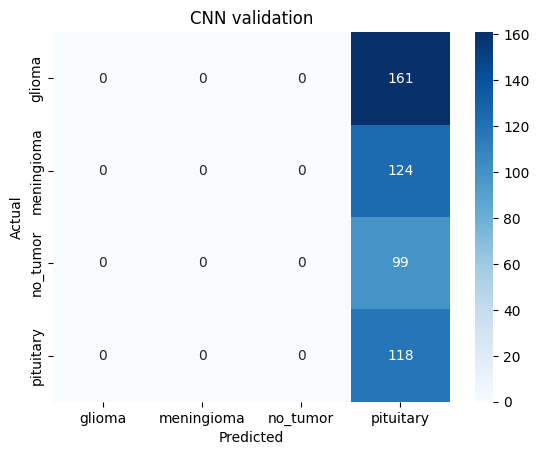

MobileNetV2 validation accuracy 0.8266932270916335 weighted P/R/F1 0.8492016159503694 0.8266932270916335 0.8239022474025223 macro F1 0.8187941050783641
              precision    recall  f1-score   support

      glioma       0.96      0.89      0.92       161
  meningioma       0.83      0.57      0.68       124
    no_tumor       0.91      0.84      0.87        99
   pituitary       0.67      1.00      0.80       118

    accuracy                           0.83       502
   macro avg       0.84      0.82      0.82       502
weighted avg       0.85      0.83      0.82       502



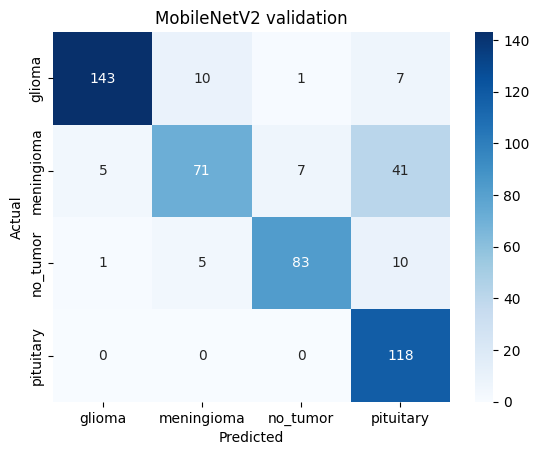

,model,accuracy,precision_weighted,recall_weighted,f1_weighted,f1_macro
0,CNN validation,0.235060,0.055253,0.235060,0.089474,0.095161
1,MobileNetV2 validation,0.826693,0.849202,0.826693,0.823902,0.818794


Selected model test accuracy 0.8170731707317073 weighted P/R/F1 0.8543674565199395 0.8170731707317073 0.8184944726772511 macro F1 0.8134244437184239
              precision    recall  f1-score   support

      glioma       0.96      0.86      0.91        80
  meningioma       0.86      0.60      0.71        63
    no_tumor       0.93      0.82      0.87        49
   pituitary       0.62      1.00      0.77        54

    accuracy                           0.82       246
   macro avg       0.84      0.82      0.81       246
weighted avg       0.85      0.82      0.82       246



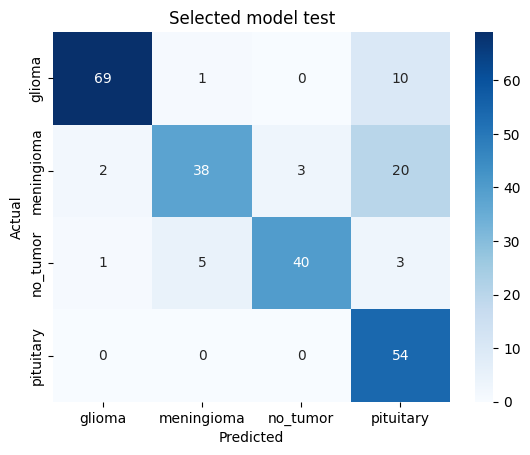

,model,accuracy,precision_weighted,recall_weighted,f1_weighted,f1_macro
0,Selected model test,0.817073,0.854367,0.817073,0.818494,0.813424


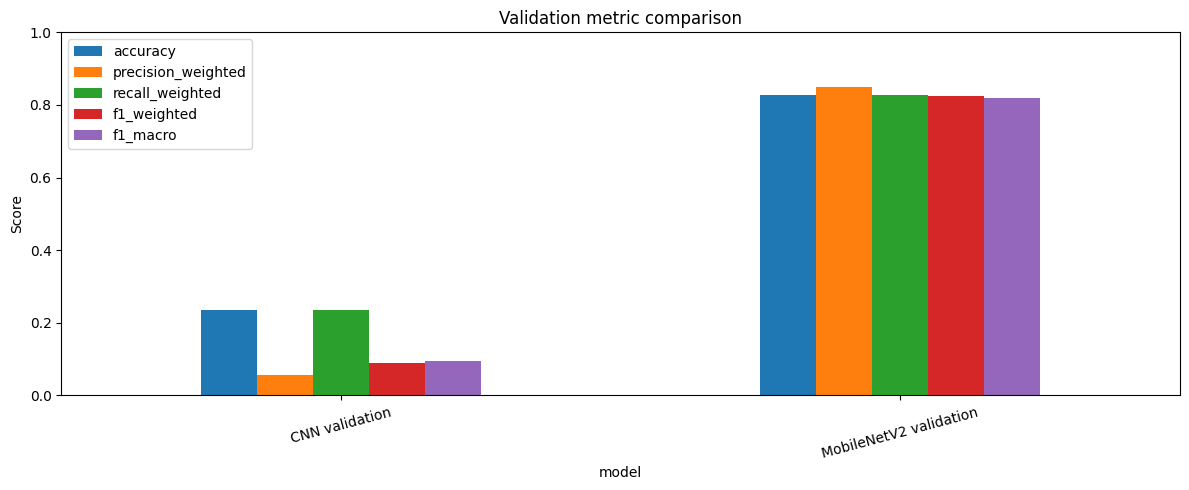

In [ ]:
def predictions(model,frame): return model.predict(dataset(frame),verbose=0).argmax(1)
def evaluate(model,frame,name):
    y=frame.label.map(label_id).to_numpy(); pred=predictions(model,frame)
    p,r,f,_=precision_recall_fscore_support(y,pred,average='weighted',zero_division=0); mf=precision_recall_fscore_support(y,pred,average='macro',zero_division=0)[2]
    print(name,'accuracy',accuracy_score(y,pred),'weighted P/R/F1',p,r,f,'macro F1',mf)
    print(classification_report(y,pred,labels=np.arange(n),target_names=class_names,zero_division=0))
    sns.heatmap(confusion_matrix(y,pred,labels=np.arange(n)),annot=True,fmt='d',xticklabels=class_names,yticklabels=class_names,cmap='Blues'); plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title(name); plt.show()
    return {'model':name,'accuracy':accuracy_score(y,pred),'precision_weighted':p,'recall_weighted':r,'f1_weighted':f,'f1_macro':mf}
# Validation set is used to choose deployment candidate.
val_results=pd.DataFrame([evaluate(cnn,val_df,'CNN validation'),evaluate(tl,val_df,'MobileNetV2 validation')]); display(val_results)
best=cnn if val_results.f1_macro.iloc[0]>=val_results.f1_macro.iloc[1] else tl
# Final held-out evaluation is done only after candidate selection.
test_results=pd.DataFrame([evaluate(best,test_df,'Selected model test')]); display(test_results)
val_results.set_index('model')[['accuracy','precision_weighted','recall_weighted','f1_weighted','f1_macro']].plot.bar(figsize=(12,5),ylim=(0,1),title='Validation metric comparison')
plt.ylabel('Score'); plt.xticks(rotation=15); plt.tight_layout(); plt.show()


**OUTPUT INSIGHT 1**


The custom CNN’s validation predictions have collapsed to a single class: pituitary. In the confusion matrix, every image is placed in the pituitary column. The model correctly identifies all 118 actual pituitary images, but also labels all 161 glioma, 124 meningioma, and 99 no-tumor images as pituitary. It makes 118 correct predictions out of 502, giving 23.5% accuracy.
The classification report confirms this pattern. Glioma, meningioma, and no tumor each have zero precision, recall, and F1 because the model never predicts those classes. Pituitary has 100% recall because it finds every actual pituitary example, but only 23.5% precision because most images it calls pituitary belong to another class. The model’s weighted F1 is about 0.09, and macro F1 is about 0.10, both indicating poor validation performance. Its accuracy is also below the 32.1% that would result from always guessing glioma, the most common validation class.
This result is consistent with the earlier custom-CNN training history: its lowest validation loss occurred at the first epoch, when validation accuracy was about 23.5%. Because the callbacks monitor validation loss and restore the best weights, the evaluated CNN may have reverted to that first-epoch state—even though validation accuracy briefly rose in a later epoch. The metrics and confusion matrix describe the model’s behavior; they do not indicate a problem with the matrix itself.
Conclusion: the custom CNN is not performing adequately on the validation set and should not be selected for deployment based on these results. Compare it with MobileNetV2 using validation macro F1 and per-class results, then evaluate the chosen candidate on the held-out test set. Before retraining, also check the label-to-index mapping and predictions on the training set to confirm the single-class behavior is not caused by an input or label-pipeline issue.

**OUTPUT INSIGHT 2**

MobileNetV2 correctly classifies 415 of the 502 validation images, giving 82.7% accuracy. The confusion matrix shows 87 errors. This is a strong improvement over the custom CNN’s validation result, which predicted every image as pituitary and achieved 23.5% accuracy. These are validation results, however; the held-out test set is still needed for final reporting.
Performance varies by class. Glioma is classified most consistently: 143 of 161 images are correct, giving 88.8% recall, while precision is 96.0%. No tumor has 83 of 99 correct, giving 83.8% recall and 91.2% precision. Pituitary has 118 of 118 correct, so its recall is 100%; however, the model also incorrectly predicts pituitary for 58 images from other classes, giving pituitary a lower precision of 67.0%.
Meningioma is the main weakness. The model correctly identifies 71 of 124 meningioma images, for 57.3% recall. It misclassifies 41 as pituitary, 7 as no tumor, and 5 as glioma. The 41 meningioma-to-pituitary errors are the largest off-diagonal value in the matrix and are the clearest area for further investigation.
The weighted F1-score is 82.4%, while macro F1 is 81.9%. These similar values suggest that overall performance is not being driven only by the largest class. Still, the class-wise results reveal the weak meningioma recall, which an overall accuracy score would not explain by itself. The model also predicts pituitary more often than its actual validation count: 176 predictions versus 118 actual pituitary images.

**OUTPUT INSIGHT 3**

The validation comparison selected MobileNetV2 over the custom CNN. On validation data, MobileNetV2 achieved 82.7% accuracy and 81.9% macro F1, while the custom CNN achieved only 23.5% accuracy and 9.5% macro F1. The custom CNN’s poor score matches its confusion matrix, where it predicted every validation image as pituitary.
On the held-out test set, the selected MobileNetV2 model correctly classified 201 of 246 images, for 81.7% accuracy. Its weighted F1 is 81.8%, and its macro F1 is 81.3%. Test accuracy is about one percentage point lower than validation accuracy, and macro F1 is also slightly lower. This close agreement suggests the validation performance carried over reasonably well to this test set, though it does not establish performance on other datasets or clinical settings.
The class-level results show that performance is uneven. Glioma has strong results: 69 of 80 cases are correct, with 86% recall and 96% precision. No tumor has 40 of 49 correct, with 82% recall and 93% precision. Meningioma is the weakest class by recall: 38 of 63 are correct, or 60%; 20 are misclassified as pituitary. Pituitary has 54 of 54 correct, giving 100% recall, but the model also predicts pituitary for 33 non-pituitary images. This lowers pituitary precision to 62%.
The confusion matrix shows these patterns directly. Its diagonal contains correct predictions: 69 glioma, 38 meningioma, 40 no tumor, and 54 pituitary. The most frequent error is meningioma predicted as pituitary (20 cases), followed by glioma predicted as pituitary (10 cases). Overall, the model tends to predict pituitary more often than the actual test count: 87 pituitary predictions versus 54 actual pituitary cases

**OUTPUT INSIGHT 4**

The bar chart compares the validation metrics of the custom CNN and MobileNetV2. The row above it reports the selected model’s test metrics. These are different evaluation sets, so interpret the chart as the model-selection comparison and the table as the final held-out check.
On validation, MobileNetV2 scores about 0.82–0.85 across all five metrics: accuracy is 0.827, weighted precision 0.849, weighted recall 0.827, weighted F1 0.824, and macro F1 0.819. Its bars are consistently high, suggesting stronger and more even validation performance across the classes.
The custom CNN performs poorly on validation: accuracy is 0.235, weighted precision 0.055, weighted recall 0.235, weighted F1 0.089, and macro F1 0.095. This matches its confusion matrix, which showed it predicted every validation image as pituitary. MobileNetV2’s accuracy is therefore about 59 percentage points higher, and its macro F1 is about 72 percentage points higher. This indicates that MobileNetV2 distinguishes the classes far more effectively on this validation set.
The table reports the selected model’s test accuracy as 0.817, weighted precision as 0.854, weighted recall as 0.817, weighted F1 as 0.818, and macro F1 as 0.813. These results are close to MobileNetV2’s validation scores, with accuracy and macro F1 slightly lower on test. That similarity is encouraging for this dataset, while the remaining difference is normal between separate samples. The earlier class report and confusion matrix still matter: meningioma recall was weaker and some non-pituitary cases were predicted as pituitary

**Reading the model evaluation graphs**
Validation metric comparison: The grouped bars compare accuracy, weighted precision/recall/F1, and macro F1. Macro F1 gives each class equal weight, so it can reveal uneven class performance that weighted metrics may hide. Use this validation comparison to select a candidate model; the test set is reserved for final evaluation.
Confusion matrices: Each matrix compares actual labels (rows) with predicted labels (columns). Strong diagonal counts indicate correct classifications. Off-diagonal counts show which categories the model confuses and can guide review of labels, image quality, and class-specific data. Check both models for categories with repeated errors; do not interpret a good overall score as proof that every class performs well.

**STATISTICAL TEST**

A statistical test is a method for using sample data to assess a specific claim. In this project, statistical tests examine patterns in the MRI dataset and compare model errors. Each test begins with a null hypothesis—the default claim being assessed—and an alternative hypothesis, which describes a difference or association the test may detect.
A test calculates a test statistic and a p-value. The p-value estimates how surprising results at least this extreme would be if the null hypothesis were true, assuming the test’s conditions hold. A common threshold is α = 0.05: if the p-value is below this threshold, the result is called statistically significant and the null hypothesis is rejected. If it is at or above 0.05, we do not reject the null hypothesis; that does not prove the null hypothesis is true. A p-value also does not measure the importance, safety, or clinical usefulness of a result.

This project uses three statistical checks:

- **Chi-square goodness-of-fit test**: compares the observed number of images in each class with an equal-count expectation. Its null hypothesis is that all four class frequencies are equal. Since the dataset’s classes have different counts, a significant result would indicate that the class distribution differs from equal representation.
- **One-way ANOVA**: compares the mean image brightness across the four classes. Its null hypothesis is that all class mean brightness values are equal; the alternative is that at least one class mean differs. A significant ANOVA indicates a difference somewhere among the class means, but does not identify which classes differ. It also relies on assumptions such as independent observations and suitably behaved within-class distributions.
- **Exact McNemar test**: compares the two models’ correctness on the same test images. It focuses on discordant cases—images one model classified correctly and the other classified incorrectly. Its null hypothesis is that the models are equally likely to be correct among those discordant cases. This paired comparison is more appropriate than treating the models’ test results as independent.

In [ ]:
from scipy.stats import chisquare, f_oneway, binomtest
from PIL import Image
import numpy as np
import pandas as pd

# H0: class frequencies are equal across classes.
observed = (
    df["label"]
    .value_counts()
    .reindex(class_names, fill_value=0)
    .to_numpy()
)
expected = np.full(len(class_names), observed.sum() / len(class_names))
chi2_stat, p_class = chisquare(observed, f_exp=expected)
print(f"Class-frequency chi-square: statistic={chi2_stat:.3f}, p={p_class:.6g}")

# H0: mean grayscale brightness is equal across classes.
brightness_rows = []

for row in df.itertuples():
    with Image.open(row.filepath) as image:
        gray = np.asarray(image.convert("L").resize(IMG_SIZE))
        brightness_rows.append((row.label, float(gray.mean() / 255.0)))

brightness_df = pd.DataFrame(brightness_rows, columns=["label", "brightness"])
brightness_groups = [
    group["brightness"].to_numpy()
    for _, group in brightness_df.groupby("label")
]

if len(brightness_groups) >= 2 and all(len(group) > 1 for group in brightness_groups):
    f_stat, p_brightness = f_oneway(*brightness_groups)
    print(f"Brightness ANOVA: F={f_stat:.3f}, p={p_brightness:.6g}")
else:
    print("Brightness ANOVA skipped: each class needs at least two images.")

# H0: the two models have equal error rates on paired test images.
y_true = test_df["label"].map(label_id).to_numpy()
cnn_correct = predictions(cnn, test_df) == y_true
tl_correct = predictions(tl, test_df) == y_true

cnn_only_correct = int(np.sum(cnn_correct & ~tl_correct))
tl_only_correct = int(np.sum(~cnn_correct & tl_correct))
discordant = cnn_only_correct + tl_only_correct

if discordant:
    p_mcnemar = binomtest(
        min(cnn_only_correct, tl_only_correct),
        n=discordant,
        p=0.5,
        alternative="two-sided",
    ).pvalue
    print(
        f"McNemar exact test: CNN-only correct={cnn_only_correct}, "
        f"MobileNetV2-only correct={tl_only_correct}, p={p_mcnemar:.6g}"
    )
else:
    print("McNemar test: the models have no discordant test predictions.")

Class-frequency chi-square: statistic=95.582, p=1.38427e-20
Brightness ANOVA: F=598.519, p=1.66774e-291
McNemar exact test: CNN-only correct=0, MobileNetV2-only correct=147, p=1.12104e-44


**INSIGHT OF THE OUTPUT**

The class-frequency chi-square test gives a statistic of 95.582 and a p-value of 1.38 × 10⁻²⁰. This p-value is far below the common 0.05 threshold, so the equal-class-count hypothesis is rejected: the four classes are not equally represented. This confirms the imbalance seen in the class-count chart. It does not mean the dataset is unusable; it means class-wise metrics and the training class weights matter when interpreting model results.


The brightness ANOVA gives F = 598.519 and p = 1.67 × 10⁻²⁹¹. This is strong evidence that average image brightness is not the same across all four classes; at least one class mean differs. ANOVA does not reveal which classes differ, or why. To determine that, a post-hoc comparison such as Tukey’s HSD would be needed. Brightness differences may also reflect scan orientation, framing, background, or image acquisition—not necessarily class-specific anatomy.


The exact McNemar test compares the two models on the same test images. It reports 147 cases correctly classified by MobileNetV2 but not by the CNN, and zero cases correctly classified by the CNN but not MobileNetV2. The p-value, 1.12 × 10⁻⁴⁴, is far below 0.05, providing strong evidence that the models’ error patterns differ and that the discordant cases favor MobileNetV2. Combined with the test confusion matrix, which shows MobileNetV2 correctly classified 201 of 246 images, these counts imply that 54 images were correctly classified by both models and the CNN made 54 correct predictions in total, assuming the outputs come from the same test run.


These tests describe this dataset and model comparison. Statistical significance does not show that brightness causes the class labels, nor does it establish clinical reliability.

**Save model, labels, and single-image inference**

In [ ]:
MODEL_PATH=OUT/'brain_tumor_classifier.keras'; LABEL_PATH=OUT/'class_names.json'
best.save(MODEL_PATH); LABEL_PATH.write_text(json.dumps(class_names,indent=2))
def predict_image(path):
    x=keras.utils.img_to_array(keras.utils.load_img(path,target_size=IMG_SIZE)).astype('float32')/255.
    prob=best.predict(x[None,...],verbose=0)[0]
    return sorted(zip(class_names,map(float,prob)),key=lambda v:v[1],reverse=True)
print('Saved',MODEL_PATH,LABEL_PATH)
# Optional: IMAGE_PATH='/content/image.jpg'; print(predict_image(IMAGE_PATH))
from google.colab import files
files.download(str(MODEL_PATH)); files.download(str(LABEL_PATH))

Saved /content/brain_tumor_outputs/brain_tumor_classifier.keras /content/brain_tumor_outputs/class_names.json


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Streamlit app code**
This cell writes app.py. Place it beside the downloaded model and class-name JSON, install TensorFlow, Streamlit, NumPy, and Pillow, then run streamlit run app.py.

In [ ]:
app_code = """import json
from pathlib import Path
import numpy as np
import streamlit as st
import tensorflow as tf
from PIL import Image
HERE=Path(__file__).parent
MODEL=tf.keras.models.load_model(HERE/'brain_tumor_classifier.keras')
CLASSES=json.loads((HERE/'class_names.json').read_text())
SIZE=(224,224)
st.set_page_config(page_title='Brain MRI Classifier',page_icon='🧠')
st.title('Brain Tumor MRI Classifier')
st.warning('Educational research prototype only. Not for diagnosis or treatment decisions. Have images reviewed by a qualified clinician.')
f=st.file_uploader('Upload MRI image',type=['jpg','jpeg','png','bmp','webp'])
if f:
 im=Image.open(f).convert('RGB'); st.image(im,use_container_width=True)
 x=np.asarray(im.resize(SIZE),dtype=np.float32)/255.0; p=MODEL.predict(x[None,...],verbose=0)[0]; order=np.argsort(p)[::-1]
 st.subheader('Predicted class: '+CLASSES[order[0]]); st.metric('Model confidence',f'{p[order[0]]:.1%}')
 st.bar_chart({CLASSES[i]:float(p[i]) for i in order})
"""
(OUT/'app.py').write_text(app_code,encoding='utf-8')
print('Created',OUT/'app.py')

Created /content/brain_tumor_outputs/app.py


 **CONCLUSION**
This project implemented an end-to-end deep-learning workflow for classifying brain MRI images into four dataset categories: glioma, meningioma, no tumor, and pituitary. The dataset contained 2,443 images across the supplied training, validation, and test partitions. The workflow included image inventory and label checks, duplicate detection, image-property analysis, visualization, resizing and normalization, training-only augmentation, model training, evaluation, and preparation of a Streamlit demonstration app. No exact duplicate image files were found, and the images had consistent source dimensions of 640 × 640 pixels.
The project compared a custom CNN with MobileNetV2 transfer learning. The custom CNN performed poorly on validation data, achieving 23.5% accuracy and predicting every validation image as pituitary. MobileNetV2 performed substantially better, achieving 82.7% validation accuracy and 81.9% macro F1. It was selected using validation results and then evaluated on the held-out test set, where it correctly classified 201 of 246 images, achieving 81.7% accuracy and 81.3% macro F1. The closeness of the validation and test scores is encouraging for this dataset, but does not establish performance on other data sources.
Class-level results show where further work is needed. The test model identified all 54 pituitary images, but its pituitary precision was 62%, because it also incorrectly classified some other categories as pituitary. Meningioma recall was the lowest at 60%; 20 of the 63 meningioma images were classified as pituitary. These errors show why per-class metrics and confusion matrices are important alongside overall accuracy. The findings support MobileNetV2 as the stronger candidate for this project’s demonstration, while also indicating that meningioma-versus-pituitary errors deserve further investigation.
The trained model, class labels, and Streamlit application code were prepared for demonstration. The application displays model predictions and confidence scores, but these outputs are not medical diagnoses. The project is limited to the supplied dataset and its partitions. Generalization to different hospitals, scanners, populations, or imaging protocols has not been established; any clinical consideration would require independent validation, domain-expert review, and appropriate oversight.